# **Deep Neural Networks - Programming Assignment**

**RNN, LSTM, GRU and Transformer**

Student Name: Sithara N T

Student ID: 2026AJ05271

# New Section

In [22]:
!pip install -q numpy pandas scikit-learn matplotlib seaborn tqdm

**Attention from scratch**

In [23]:
%%writefile attention.py
import math
import torch
import torch.nn.functional as F


def scaled_dot_product_attention(q, k, v, mask=None):
    """
    q, k, v: [B, H, T, D]
    mask: [T, T] boolean tensor.
          True  = attention allowed
          False = attention masked
    """
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask.bool(), float("-inf"))

    weights = F.softmax(scores, dim=-1)
    output = weights @ v

    return output, weights


def make_causal_mask(t, device=None):
    """
    Position i may attend only to positions j <= i.
    """
    return torch.tril(
        torch.ones(t, t, dtype=torch.bool, device=device)
    )

Overwriting attention.py


**Test attention**

In [24]:
import torch
import torch.nn.functional as F
from attention import scaled_dot_product_attention, make_causal_mask


def test_attention():
    torch.manual_seed(0)

    B, H, T, D = 2, 3, 4, 8
    q = torch.randn(B, H, T, D)
    k = torch.randn(B, H, T, D)
    v = torch.randn(B, H, T, D)

    # 1. Every row of attention weights sums to 1.
    _, weights = scaled_dot_product_attention(q, k, v)

    assert torch.allclose(
        weights.sum(dim=-1),
        torch.ones(B, H, T),
        atol=1e-6
    )

    # 2. Match PyTorch built-in attention.
    reference = F.scaled_dot_product_attention(q, k, v)
    ours, _ = scaled_dot_product_attention(q, k, v)

    assert torch.allclose(ours, reference, atol=1e-5)

    # 3. Causal mask gives zero weight to future positions.
    causal_mask = make_causal_mask(T, q.device)
    _, causal_weights = scaled_dot_product_attention(
        q, k, v, mask=causal_mask
    )

    future_positions = torch.triu(
        torch.ones(T, T, dtype=torch.bool),
        diagonal=1
    )

    assert (causal_weights[..., future_positions] == 0).all()

    print("All attention unit tests passed.")


def hand_check():
    q = torch.tensor([
        [1.0, 0.0],
        [0.0, 1.0],
        [1.0, 1.0]
    ]).unsqueeze(0).unsqueeze(0)

    k = q.clone()

    v = torch.tensor([
        [1.0, 2.0],
        [3.0, 4.0],
        [5.0, 6.0]
    ]).unsqueeze(0).unsqueeze(0)

    output, weights = scaled_dot_product_attention(q, k, v)

    print("Hand-check attention weights:")
    print(weights.squeeze())

    print("\nHand-check output:")
    print(output.squeeze())


test_attention()
hand_check()

All attention unit tests passed.
Hand-check attention weights:
tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]])

Hand-check output:
tensor([[3.0000, 4.0000],
        [3.4067, 4.4067],
        [3.5105, 4.5105]])


**Multi-head attention and encoder**

In [25]:
%%writefile transformer.py
import math
import torch
import torch.nn as nn

from attention import (
    scaled_dot_product_attention,
    make_causal_mask
)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads

        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, T, _ = x.shape

        q = self.w_q(x).view(
            B, T, self.n_heads, self.d_head
        ).transpose(1, 2)

        k = self.w_k(x).view(
            B, T, self.n_heads, self.d_head
        ).transpose(1, 2)

        v = self.w_v(x).view(
            B, T, self.n_heads, self.d_head
        ).transpose(1, 2)

        out, weights = scaled_dot_product_attention(
            q, k, v, mask=mask
        )

        out = out.transpose(1, 2).contiguous().view(
            B, T, self.d_model
        )

        return self.dropout(self.w_o(out)), weights


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(
            d_model, n_heads, dropout
        )

        self.ln2 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        attn_out, weights = self.attn(
            self.ln1(x), mask=mask
        )

        x = x + self.dropout(attn_out)
        x = x + self.ff(self.ln2(x))

        return x, weights


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len).unsqueeze(1).float()

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class LearnedPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        self.pos = nn.Embedding(max_len, d_model)

    def forward(self, x):
        positions = torch.arange(
            x.size(1), device=x.device
        )

        return x + self.pos(positions)


class TransformerEncoder(nn.Module):
    def __init__(
        self,
        input_dim,
        d_model=128,
        n_heads=4,
        n_layers=4,
        d_ff=512,
        dropout=0.1,
        pos_encoding="sinusoidal",
        max_len=5000,
    ):
        super().__init__()

        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoding = pos_encoding

        if pos_encoding == "sinusoidal":
            self.pos = SinusoidalPositionalEncoding(
                d_model, max_len
            )

        elif pos_encoding == "learned":
            self.pos = LearnedPositionalEncoding(
                d_model, max_len
            )

        elif pos_encoding == "none":
            self.pos = None

        else:
            raise ValueError(
                "pos_encoding must be none, sinusoidal, or learned"
            )

        self.cls = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        self.blocks = nn.ModuleList([
            EncoderBlock(
                d_model, n_heads, d_ff, dropout
            )
            for _ in range(n_layers)
        ])

        self.ln = nn.LayerNorm(d_model)

    def forward(self, x, padding_mask=None):
        B, T, _ = x.shape

        x = self.input_proj(x)

        if self.pos is not None:
            x = self.pos(x)

        cls = self.cls.expand(B, 1, -1)
        x = torch.cat([cls, x], dim=1)

        if padding_mask is not None:
            cls_mask = torch.ones(
                B, 1,
                dtype=torch.bool,
                device=x.device
            )

            padding_mask = torch.cat(
                [cls_mask, padding_mask], dim=1
            )

            mask = padding_mask.unsqueeze(1).unsqueeze(2)
            mask = mask & mask.transpose(-2, -1)

        else:
            mask = None

        weights = []

        for block in self.blocks:
            x, w = block(x, mask=mask)
            weights.append(w)

        return self.ln(x[:, 0]), weights


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(
            d_model, n_heads, dropout
        )

    def forward(self, x):
        B, T, _ = x.shape
        mask = make_causal_mask(T, device=x.device)

        out, weights = self.attn(x, mask=mask)
        return out, weights


class CausalBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(
            d_model, n_heads, dropout
        )

        self.ln2 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        attn_out, weights = self.attn(self.ln1(x))

        x = x + self.dropout(attn_out)
        x = x + self.ff(self.ln2(x))

        return x, weights


class CharTransformerLM(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=128,
        n_heads=4,
        n_layers=4,
        d_ff=512,
        context=128,
        dropout=0.1,
    ):
        super().__init__()

        self.context = context

        self.token_embedding = nn.Embedding(
            vocab_size, d_model
        )

        self.position_embedding = nn.Embedding(
            context, d_model
        )

        self.blocks = nn.ModuleList([
            CausalBlock(
                d_model, n_heads, d_ff, dropout
            )
            for _ in range(n_layers)
        ])

        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(
            d_model, vocab_size, bias=False
        )

    def forward(self, idx, targets=None):
        B, T = idx.shape
        positions = torch.arange(T, device=idx.device)

        x = self.token_embedding(idx)
        x = x + self.position_embedding(positions)

        weights = []

        for block in self.blocks:
            x, w = block(x)
            weights.append(w)

        x = self.ln(x)
        logits = self.head(x)

        loss = None

        if targets is not None:
            loss = torch.nn.functional.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss, weights

    @torch.no_grad()
    def generate(
        self,
        idx,
        max_new_tokens,
        temperature=1.0,
        top_k=None,
    ):
        self.eval()

        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context:]

            logits, _, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-8)

            if top_k is not None:
                values, _ = torch.topk(logits, top_k)
                logits[logits < values[:, [-1]]] = float("-inf")

            probs = torch.nn.functional.softmax(
                logits, dim=-1
            )

            next_token = torch.multinomial(
                probs, num_samples=1
            )

            idx = torch.cat([idx, next_token], dim=1)

        return idx


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable

Overwriting transformer.py


**Verify encoder parameters**

In [26]:
import torch
from transformer import TransformerEncoder, count_parameters

d = 128
d_ff = 512

attention_weights = 4 * d * d
ff_weights = 2 * d * d_ff

attention_biases = 4 * d
ff_biases = d_ff + d
layer_norm_parameters = 2 * (2 * d)

core_weights = attention_weights + ff_weights
block_total = (
    core_weights
    + attention_biases
    + ff_biases
    + layer_norm_parameters
)

print("Attention weights:", attention_weights)
print("Feed-forward weights:", ff_weights)
print("Core weights per block:", core_weights)

assert core_weights == 196608

print("Attention biases:", attention_biases)
print("Feed-forward biases:", ff_biases)
print("LayerNorm parameters:", layer_norm_parameters)
print("Total parameters per encoder block:", block_total)

assert block_total == 198272

model = TransformerEncoder(
    input_dim=8,
    d_model=d,
    n_heads=4,
    n_layers=1,
    d_ff=d_ff,
    pos_encoding="none"
)

total, trainable = count_parameters(model)

input_projection = 8 * d + d
cls_token = d
final_layer_norm = 2 * d

print("\nFull one-layer HAR encoder:")
print("Encoder block:", block_total)
print("Input projection:", input_projection)
print("CLS token:", cls_token)
print("Final LayerNorm:", final_layer_norm)
print("Expected full-model total:", block_total + input_projection + cls_token + final_layer_norm)
print("Reported total:", total)
print("Reported trainable:", trainable)

assert total == block_total + input_projection + cls_token + final_layer_norm

x = torch.randn(2, 70, 8)
logits, weights = model(x)

print("\nOutput shape:", logits.shape)
print("Number of attention layers:", len(weights))

Attention weights: 65536
Feed-forward weights: 131072
Core weights per block: 196608
Attention biases: 512
Feed-forward biases: 640
LayerNorm parameters: 512
Total parameters per encoder block: 198272

Full one-layer HAR encoder:
Encoder block: 198272
Input projection: 1152
CLS token: 128
Final LayerNorm: 256
Expected full-model total: 199808
Reported total: 199808
Reported trainable: 199808

Output shape: torch.Size([2, 128])
Number of attention layers: 1


**HAR encoder classifier**

In [27]:
%%writefile har.py
import os
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score
from tqdm import tqdm

from transformer import TransformerEncoder, count_parameters


HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

HAR_ZIP = "har.zip"
HAR_DIR = "UCI HAR Dataset"


def download_har():
    if not os.path.exists(HAR_ZIP):
        print("Downloading UCI HAR dataset...")
        urllib.request.urlretrieve(HAR_URL, HAR_ZIP)

    if not os.path.exists(HAR_DIR):
        print("Extracting UCI HAR dataset...")
        with zipfile.ZipFile(HAR_ZIP) as z:
            z.extractall(".")


def load_har():
    download_har()

    X_train = pd.read_csv(
        f"{HAR_DIR}/train/X_train.txt",
        sep=r"\s+",
        header=None
    ).to_numpy(dtype=np.float32)

    y_train = pd.read_csv(
        f"{HAR_DIR}/train/y_train.txt",
        sep=r"\s+",
        header=None
    ).to_numpy().ravel().astype(np.int64) - 1

    X_test = pd.read_csv(
        f"{HAR_DIR}/test/X_test.txt",
        sep=r"\s+",
        header=None
    ).to_numpy(dtype=np.float32)

    y_test = pd.read_csv(
        f"{HAR_DIR}/test/y_test.txt",
        sep=r"\s+",
        header=None
    ).to_numpy().ravel().astype(np.int64) - 1

    return X_train, y_train, X_test, y_test


def train_har_model(
    pos_encoding="sinusoidal",
    patch_size=8,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    epochs=10,
    batch_size=64,
    lr=3e-4,
    device=None,
):
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"

    X_train, y_train, X_test, y_test = load_har()

    n_patches = X_train.shape[1] // patch_size
    X_train = X_train[:, :n_patches * patch_size]
    X_test = X_test[:, :n_patches * patch_size]

    X_train = X_train.reshape(-1, n_patches, patch_size)
    X_test = X_test.reshape(-1, n_patches, patch_size)

    train_dataset = TensorDataset(
        torch.from_numpy(X_train),
        torch.from_numpy(y_train)
    )

    test_dataset = TensorDataset(
        torch.from_numpy(X_test),
        torch.from_numpy(y_test)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size
    )

    model = TransformerEncoder(
        input_dim=patch_size,
        d_model=d_model,
        n_heads=n_heads,
        n_layers=n_layers,
        d_ff=d_ff,
        dropout=0.1,
        pos_encoding=pos_encoding,
        max_len=n_patches + 1,
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    total_params, trainable_params = count_parameters(model)
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        losses = []

        for xb, yb in tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}"
        ):
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits, _ = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()
            losses.append(loss.item())

        scheduler.step()

        print(
            f"Epoch {epoch + 1}: "
            f"loss={np.mean(losses):.4f}, "
            f"lr={scheduler.get_last_lr()[0]:.6f}"
        )

    training_time = time.time() - start_time

    model.eval()
    predictions = []
    targets = []

    with torch.no_grad():
        for xb, yb in test_loader:
            logits, _ = model(xb.to(device))
            predictions.extend(
                logits.argmax(dim=-1).cpu().numpy()
            )
            targets.extend(yb.numpy())

    accuracy = accuracy_score(targets, predictions)

    result = {
        "pos_encoding": pos_encoding,
        "patch_size": patch_size,
        "accuracy": accuracy,
        "parameters": total_params,
        "trainable_parameters": trainable_params,
        "training_time_sec": training_time,
    }

    print(result)

    return model, result

Overwriting har.py


In [28]:
%%writefile har.py
import os
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score
from tqdm import tqdm

from transformer import TransformerEncoder, count_parameters

HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

HAR_ZIP = "har.zip"
HAR_DIR = "UCI HAR Dataset"

def download_har():
    if not os.path.exists(HAR_ZIP):
        print("Downloading UCI HAR dataset...")
        urllib.request.urlretrieve(HAR_URL, HAR_ZIP)

    if not os.path.exists(HAR_DIR):
        print("Extracting outer UCI HAR dataset...")
        with zipfile.ZipFile(HAR_ZIP) as z:
            z.extractall(".")

    # Handle nested zip if it exists
    nested_zip = "UCI HAR Dataset.zip"
    if os.path.exists(nested_zip) and not os.path.exists(HAR_DIR):
        print("Extracting nested UCI HAR Dataset.zip...")
        with zipfile.ZipFile(nested_zip, "r") as z:
            z.extractall(".")

def load_har():
    download_har()

    X_train = pd.read_csv(
        f"{HAR_DIR}/train/X_train.txt",
        sep=r"\s+",
        header=None
    ).to_numpy(dtype=np.float32)

    y_train = pd.read_csv(
        f"{HAR_DIR}/train/y_train.txt",
        sep=r"\s+",
        header=None
    ).to_numpy().ravel().astype(np.int64) - 1

    X_test = pd.read_csv(
        f"{HAR_DIR}/test/X_test.txt",
        sep=r"\s+",
        header=None
    ).to_numpy(dtype=np.float32)

    y_test = pd.read_csv(
        f"{HAR_DIR}/test/y_test.txt",
        sep=r"\s+",
        header=None
    ).to_numpy().ravel().astype(np.int64) - 1

    return X_train, y_train, X_test, y_test

def train_har_model(
    pos_encoding="sinusoidal",
    patch_size=8,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    epochs=10,
    batch_size=64,
    lr=3e-4,
    device=None,
):
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"

    X_train, y_train, X_test, y_test = load_har()

    n_patches = X_train.shape[1] // patch_size
    X_train = X_train[:, :n_patches * patch_size]
    X_test = X_test[:, :n_patches * patch_size]

    X_train = X_train.reshape(-1, n_patches, patch_size)
    X_test = X_test.reshape(-1, n_patches, patch_size)

    train_dataset = TensorDataset(
        torch.from_numpy(X_train),
        torch.from_numpy(y_train)
    )

    test_dataset = TensorDataset(
        torch.from_numpy(X_test),
        torch.from_numpy(y_test)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size
    )

    model = TransformerEncoder(
        input_dim=patch_size,
        d_model=d_model,
        n_heads=n_heads,
        n_layers=n_layers,
        d_ff=d_ff,
        dropout=0.1,
        pos_encoding=pos_encoding,
        max_len=n_patches + 1,
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    total_params, trainable_params = count_parameters(model)
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        losses = []

        for xb, yb in tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}"
        ):
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits, _ = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()
            losses.append(loss.item())

        scheduler.step()

        print(
            f"Epoch {epoch + 1}: "
            f"loss={np.mean(losses):.4f}, "
            f"lr={scheduler.get_last_lr()[0]:.6f}"
        )

    training_time = time.time() - start_time

    model.eval()
    predictions = []
    targets = []

    with torch.no_grad():
        for xb, yb in test_loader:
            logits, _ = model(xb.to(device))
            predictions.extend(
                logits.argmax(dim=-1).cpu().numpy()
            )
            targets.extend(yb.numpy())

    accuracy = accuracy_score(targets, predictions)

    result = {
        "pos_encoding": pos_encoding,
        "patch_size": patch_size,
        "accuracy": accuracy,
        "parameters": total_params,
        "trainable_parameters": trainable_params,
        "training_time_sec": training_time,
    }

    print(result)

    return model, result

Overwriting har.py


**Train HAR with all positional encodings**

In [29]:
import os
import zipfile
from har import train_har_model
import pandas as pd

# Fix: Extract the nested 'UCI HAR Dataset.zip' if it exists and hasn't been extracted yet
if os.path.exists("UCI HAR Dataset.zip") and not os.path.exists("UCI HAR Dataset"):
    print("Extracting nested UCI HAR Dataset.zip...")
    with zipfile.ZipFile("UCI HAR Dataset.zip", "r") as z:
        z.extractall(".")

results = []

for pos_encoding in ["none", "sinusoidal", "learned"]:
    print("\n" + "=" * 60)
    print("Training HAR model with:", pos_encoding)
    print("=" * 60)

    model, result = train_har_model(
        pos_encoding=pos_encoding,
        patch_size=8,
        d_model=128,
        n_heads=4,
        n_layers=4,
        d_ff=512,
        epochs=10,
        batch_size=64,
        lr=3e-4
    )

    results.append(result)

har_results = pd.DataFrame(results)
har_results.to_csv("har_results.csv", index=False)

har_results


Training HAR model with: none


Epoch 1/10: 100%|██████████| 115/115 [00:04<00:00, 26.88it/s]


Epoch 1: loss=1.1758, lr=0.000293


Epoch 2/10: 100%|██████████| 115/115 [00:04<00:00, 23.99it/s]


Epoch 2: loss=0.5102, lr=0.000271


Epoch 3/10: 100%|██████████| 115/115 [00:05<00:00, 21.14it/s]


... (52 outputs left out)

Epoch 9: loss=0.1236, lr=0.000007


Epoch 10/10: 100%|██████████| 115/115 [00:02<00:00, 43.69it/s]


Epoch 10: loss=0.1163, lr=0.000000
{'pos_encoding': 'learned', 'patch_size': 8, 'accuracy': 0.8822531387852053, 'parameters': 803712, 'trainable_parameters': 803712, 'training_time_sec': 22.414857387542725}


,pos_encoding,patch_size,accuracy,parameters,trainable_parameters,training_time_sec
0,none,8,0.879199,794624,794624,29.582020
1,sinusoidal,8,0.882592,794624,794624,21.451248
2,learned,8,0.882253,803712,803712,22.414857


**Character-level causal LM**

In [30]:
%%writefile shakespeare.py
import math
import os
import time
import urllib.request

import numpy as np
import torch
import torch.nn.functional as F
from tqdm import tqdm

from transformer import CharTransformerLM, count_parameters

SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "master/data/tinyshakespeare/input.txt"
)

SHAKESPEARE_FILE = "tiny_shakespeare.txt"

def download_text():
    if not os.path.exists(SHAKESPEARE_FILE):
        print("Downloading Tiny Shakespeare...")
        urllib.request.urlretrieve(
            SHAKESPEARE_URL,
            SHAKESPEARE_FILE
        )

    with open(
        SHAKESPEARE_FILE,
        "r",
        encoding="utf-8"
    ) as f:
        return f.read()

def get_batches(data, batch_size, context, device):
    indices = torch.randint(
        len(data) - context - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + context]
        for i in indices
    ])

    y = torch.stack([
        data[i + 1:i + context + 1]
        for i in indices
    ])

    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(
    model,
    data,
    context,
    batch_size,
    device,
    iterations=50
):
    model.eval()
    losses = []

    for _ in range(iterations):
        x, y = get_batches(
            data,
            batch_size,
            context,
            device
        )

        _, loss, _ = model(x, y)
        losses.append(loss.item())

    model.train()

    return np.mean(losses)

def train_language_model(
    context=128,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    batch_size=64,
    steps=5000,
    lr=3e-4,
    device=None,
):
    if device is None:
        device = (
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        )

    torch.manual_seed(1337)

    text = download_text()

    chars = sorted(set(text))
    vocab_size = len(chars)

    stoi = {
        character: index
        for index, character in enumerate(chars)
    }

    itos = {
        index: character
        for index, character in enumerate(chars)
    }

    encoded = np.array(
        [stoi[c] for c in text],
        dtype=np.int64
    )

    split = int(0.9 * len(encoded))

    train_data = torch.from_numpy(encoded[:split])
    val_data = torch.from_numpy(encoded[split:])

    model = CharTransformerLM(
        vocab_size=vocab_size,
        d_model=d_model,
        n_heads=n_heads,
        n_layers=n_layers,
        d_ff=d_ff,
        context=context,
        dropout=0.1,
    ).to(device)

    total_params, trainable_params = count_parameters(model)

    print("Vocabulary size:", vocab_size)
    print("Total parameters:", total_params)
    print("Trainable parameters:", trainable_params)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=steps
    )

    start_time = time.time()

    train_losses = []
    val_losses = []

    for step in tqdm(range(steps)):
        x, y = get_batches(
            train_data,
            batch_size,
            context,
            device
        )

        optimizer.zero_grad()

        _, loss, _ = model(x, y)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()
        scheduler.step()

        if step % 250 == 0 or step == steps - 1:
            val_loss = estimate_loss(
                model,
                val_data,
                context,
                batch_size,
                device
            )

            train_losses.append(loss.item())
            val_losses.append(val_loss)

            bits_per_char = val_loss / math.log(2)

            print(
                f"step {step}: "
                f"train_loss={loss.item():.4f}, "
                f"val_loss={val_loss:.4f}, "
                f"bits_per_char={bits_per_char:.4f}"
            )

    training_time = time.time() - start_time
    final_val_loss = val_losses[-1]
    final_bits_per_char = final_val_loss / math.log(2)

    print("\nFinal validation loss:", final_val_loss)
    print("Final bits per character:", final_bits_per_char)
    print("Training time:", training_time)

    prompt = torch.tensor(
        [[stoi["F"]]],
        device=device
    )

    generations = {}

    for temperature in [0.2, 0.8, 1.5]:
        generated_ids = model.generate(
            prompt.clone(),
            max_new_tokens=500,
            temperature=temperature,
            top_k=40
        )[0].tolist()

        generated_text = "".join(
            itos[i] for i in generated_ids
        )

        generations[temperature] = generated_text

        print(f"\n--- Temperature {temperature} ---")
        print(generated_text)

    torch.save(
        model.state_dict(),
        "char_transformer.pt"
    )

    return {
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "final_val_loss": final_val_loss,
        "final_bits_per_char": final_bits_per_char,
        "training_time": training_time,
        "generations": generations,
        "itos": itos,
        "stoi": stoi,
    }

Overwriting shakespeare.py


In [31]:
# Cleanly prepending correct imports to transformer.py
with open('transformer.py', 'r') as f:
    content = f.read()

# Strip out any legacy broken lines of these imports to avoid duplicates
lines = [line for line in content.splitlines() if line.strip() not in ('import torch', 'import torch.nn as nn')]
fixed_content = "import torch\nimport torch.nn as nn\n" + "\n".join(lines)

with open('transformer.py', 'w') as f:
    f.write(fixed_content)

# Uncache modules so Python loads the fresh file
import sys
for mod in ['transformer', 'shakespeare']:
    if mod in sys.modules:
        del sys.modules[mod]

from shakespeare import train_language_model

shakespeare_result = train_language_model(
    context=128,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    batch_size=64,
    steps=5000,
    lr=3e-4
)

Vocabulary size: 65
Total parameters: 826368
Trainable parameters: 826368


  0%|          | 5/5000 [00:00<10:37,  7.84it/s]

step 0: train_loss=4.3390, val_loss=4.2112, bits_per_char=6.0755


  5%|▌         | 256/5000 [00:10<06:18, 12.52it/s]

step 250: train_loss=2.4771, val_loss=2.4811, bits_per_char=3.5794


 10%|█         | 506/5000 [00:19<05:59, 12.51it/s]

... (34 outputs left out)

step 4750: train_loss=1.7370, val_loss=1.7876, bits_per_char=2.5790


100%|██████████| 5000/5000 [03:04<00:00, 27.05it/s]

step 4999: train_loss=1.6922, val_loss=1.7905, bits_per_char=2.5831

Final validation loss: 1.7904966425895692
Final bits per character: 2.5831406269923103
Training time: 184.8211498260498



--- Temperature 0.2 ---
For the was the death a come the seem.

LUCIO:
I will the do the so the was the come the son.

CORIOLANUS:
The shall stand the soul the do so the words,
And the would the with of the his of the could sould and the
prove the with the do the course of the did to the strance
The sould the shall the would the with the doth streak.

DUKE VINCENTIO:
I will the was the death of her with her with the sould the bear
The would the with heart of the with the with the doth
The wast the would of the come the 

--- Temperature 0.8 ---
Fors! my say the wome, and seever
That shall he proved be the brepine not your death,
I know your more and pallount speak rest to from,
By read the are in we this all your that the way.

DUKE OVERSTERNE:
O a not, let you will a broath the bew farel'd at the
prepation sower so thou hought soul me:
O guay be your five thank he gond throw
With liber bands you pleast Shall thou son of worse have do doth
dothsudly ever love, it my list and that more

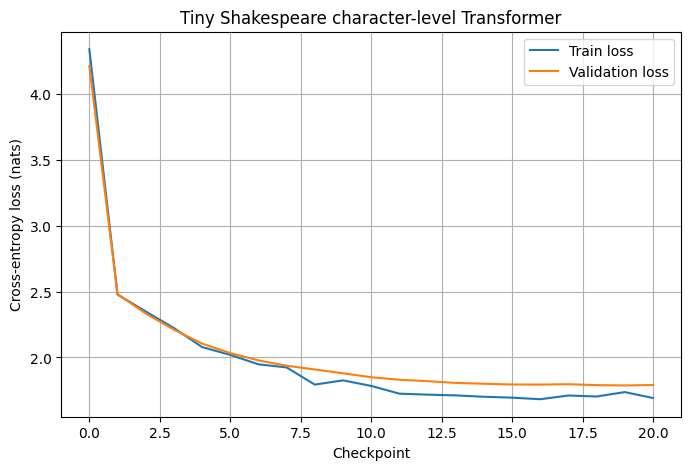

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(shakespeare_result["train_losses"], label="Train loss")
plt.plot(shakespeare_result["val_losses"], label="Validation loss")

plt.xlabel("Checkpoint")
plt.ylabel("Cross-entropy loss (nats)")
plt.title("Tiny Shakespeare character-level Transformer")
plt.legend()
plt.grid(True)
plt.savefig("shakespeare_loss.png", dpi=200, bbox_inches="tight")
plt.show()

**Analysis and ablations**

In [33]:
%%writefile analysis.py
import math
import time

import matplotlib.pyplot as plt
import seaborn as sns
import torch

from shakespeare import (
    download_text,
    get_batches
)
from transformer import CharTransformerLM


def plot_attention_heatmaps(
    model,
    text,
    stoi,
    device="cpu"
):
    model.eval()

    ids = torch.tensor(
        [[stoi[c] for c in text]],
        device=device
    )

    with torch.no_grad():
        _, _, weights = model(ids)

    for layer in [0, 3]:
        attention = weights[layer][0, 0].cpu().numpy()

        plt.figure(figsize=(8, 6))
        sns.heatmap(
            attention,
            cmap="viridis"
        )

        plt.title(
            f"Layer {layer}, Head 0 attention"
        )

        plt.xlabel("Key position")
        plt.ylabel("Query position")
        plt.tight_layout()

        plt.savefig(
            f"attention_layer_{layer}.png",
            dpi=200
        )

        plt.close()


def context_scaling_benchmark(
    vocab_size=65,
    device=None
):
    if device is None:
        device = (
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        )

    model = CharTransformerLM(
        vocab_size=vocab_size,
        context=512
    ).to(device)

    results = []

    for context in [64, 128, 256, 512]:
        x = torch.randint(
            0, vocab_size,
            (8, context),
            device=device
        )

        y = torch.randint(
            0, vocab_size,
            (8, context),
            device=device
        )

        if device == "cuda":
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        start = time.time()

        for _ in range(10):
            _, loss, _ = model(x, y)
            loss.backward()
            model.zero_grad()

        if device == "cuda":
            torch.cuda.synchronize()

        elapsed = (time.time() - start) / 10

        memory = (
            torch.cuda.max_memory_allocated() / 1024**2
            if device == "cuda"
            else float("nan")
        )

        results.append({
            "context": context,
            "seconds_per_step": elapsed,
            "peak_memory_mb": memory,
            "theoretical_attention_ops": context**2 * 128
        })

        print(results[-1])

    return results

Overwriting analysis.py


**Attention heatmaps**

In [34]:
from analysis import plot_attention_heatmaps
from shakespeare import download_text

text = download_text()

chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}

plot_attention_heatmaps(
    shakespeare_result["model"],
    "First Citizen:",
    stoi,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

print("Saved attention_layer_0.png and attention_layer_3.png")

Saved attention_layer_0.png and attention_layer_3.png


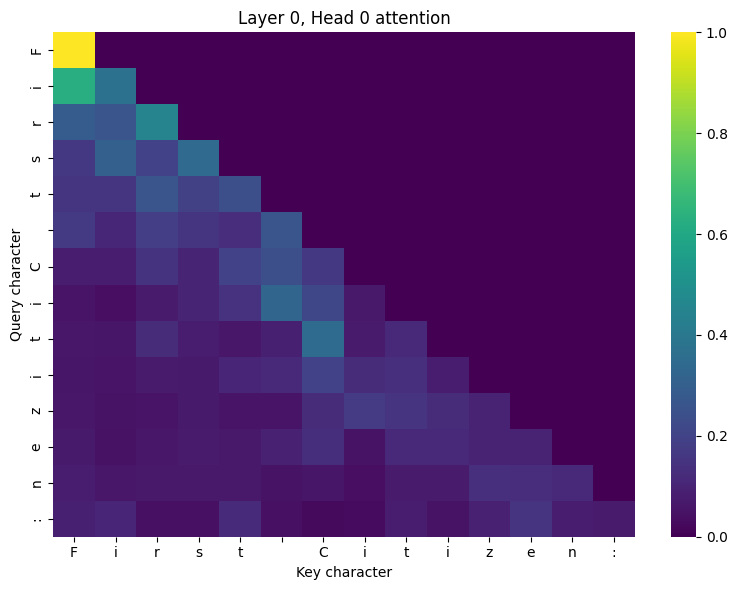

Saved: attention_layer_0_head_0.png


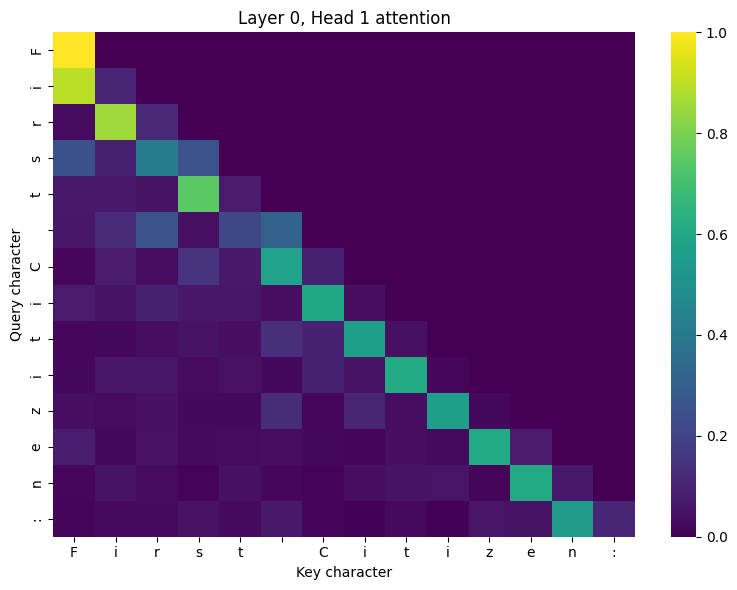

Saved: attention_layer_0_head_1.png


In [35]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from shakespeare import download_text


def plot_two_head_heatmaps(
    model,
    text,
    stoi,
    layer=0,
    heads=(0, 1),
    device="cpu"
):
    model.eval()

    ids = torch.tensor(
        [[stoi[c] for c in text]],
        device=device
    )

    with torch.no_grad():
        _, _, weights = model(ids)

    # weights[layer] has shape:
    # [batch, heads, query positions, key positions]
    attention = weights[layer][0]

    characters = list(text)

    for head in heads:
        head_weights = attention[head].cpu().numpy()

        plt.figure(figsize=(8, 6))
        sns.heatmap(
            head_weights,
            cmap="viridis",
            xticklabels=characters,
            yticklabels=characters
        )

        plt.title(
            f"Layer {layer}, Head {head} attention"
        )

        plt.xlabel("Key character")
        plt.ylabel("Query character")
        plt.tight_layout()

        filename = f"attention_layer_{layer}_head_{head}.png"
        plt.savefig(filename, dpi=200, bbox_inches="tight")
        plt.show()

        print(f"Saved: {filename}")


text = download_text()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}

plot_two_head_heatmaps(
    shakespeare_result["model"],
    "First Citizen:",
    stoi,
    layer=0,
    heads=(0, 1),
    device="cuda" if torch.cuda.is_available() else "cpu"
)

**Head-count ablation**

In [36]:
%%writefile shakespeare.py
import math
import os
import time
import urllib.request

import numpy as np
import torch
import torch.nn.functional as F
from tqdm import tqdm

from transformer import CharTransformerLM, count_parameters

SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "master/data/tinyshakespeare/input.txt"
)

SHAKESPEARE_FILE = "tiny_shakespeare.txt"

def download_text():
    if not os.path.exists(SHAKESPEARE_FILE):
        print("Downloading Tiny Shakespeare...")
        urllib.request.urlretrieve(
            SHAKESPEARE_URL,
            SHAKESPEARE_FILE
        )

    with open(
        SHAKESPEARE_FILE,
        "r",
        encoding="utf-8"
    ) as f:
        return f.read()

def get_batches(data, batch_size, context, device):
    indices = torch.randint(
        len(data) - context - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + context]
        for i in indices
    ])

    y = torch.stack([
        data[i + 1:i + context + 1]
        for i in indices
    ])

    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(
    model,
    data,
    context,
    batch_size,
    device,
    iterations=50
):
    model.eval()
    losses = []

    for _ in range(iterations):
        x, y = get_batches(
            data,
            batch_size,
            context,
            device
        )

        _, loss, _ = model(x, y)
        losses.append(loss.item())

    model.train()

    return np.mean(losses)

def train_language_model(
    context=128,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    batch_size=64,
    steps=5000,
    lr=3e-4,
    device=None,
):
    if device is None:
        device = (
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        )

    torch.manual_seed(1337)

    text = download_text()

    chars = sorted(set(text))
    vocab_size = len(chars)

    stoi = {
        character: index
        for index, character in enumerate(chars)
    }

    itos = {
        index: character
        for index, character in enumerate(chars)
    }

    encoded = np.array(
        [stoi[c] for c in text],
        dtype=np.int64
    )

    split = int(0.9 * len(encoded))

    train_data = torch.from_numpy(encoded[:split])
    val_data = torch.from_numpy(encoded[split:])

    model = CharTransformerLM(
        vocab_size=vocab_size,
        d_model=d_model,
        n_heads=n_heads,
        n_layers=n_layers,
        d_ff=d_ff,
        context=context,
        dropout=0.1,
    ).to(device)

    total_params, trainable_params = count_parameters(model)

    print("Vocabulary size:", vocab_size)
    print("Total parameters:", total_params)
    print("Trainable parameters:", trainable_params)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=steps
    )

    start_time = time.time()

    train_losses = []
    val_losses = []

    for step in tqdm(range(steps)):
        x, y = get_batches(
            train_data,
            batch_size,
            context,
            device
        )

        optimizer.zero_grad()

        _, loss, _ = model(x, y)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()
        scheduler.step()

        if step % 250 == 0 or step == steps - 1:
            val_loss = estimate_loss(
                model,
                val_data,
                context,
                batch_size,
                device
            )

            train_losses.append(loss.item())
            val_losses.append(val_loss)

            bits_per_char = val_loss / math.log(2)

            print(
                f"step {step}: "
                f"train_loss={loss.item():.4f}, "
                f"val_loss={val_loss:.4f}, "
                f"bits_per_char={bits_per_char:.4f}"
            )

    training_time = time.time() - start_time
    final_val_loss = val_losses[-1]
    final_bits_per_char = final_val_loss / math.log(2)

    print("\nFinal validation loss:", final_val_loss)
    print("Final bits per character:", final_bits_per_char)
    print("Training time:", training_time)

    prompt = torch.tensor(
        [[stoi["F"]]],
        device=device
    )

    generations = {}

    for temperature in [0.2, 0.8, 1.5]:
        generated_ids = model.generate(
            prompt.clone(),
            max_new_tokens=500,
            temperature=temperature,
            top_k=40
        )[0].tolist()

        generated_text = "".join(
            itos[i] for i in generated_ids
        )

        generations[temperature] = generated_text

        print(f"\n--- Temperature {temperature} ---")
        print(generated_text)

    torch.save(
        model.state_dict(),
        "char_transformer.pt"
    )

    return {
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "final_val_loss": final_val_loss,
        "final_bits_per_char": final_bits_per_char,
        "training_time": training_time,
        "generations": generations,
        "itos": itos,
        "stoi": stoi,
    }

# Execution script
if __name__ == "__main__":
    import sys
    # Clear cached imports
    for mod in ["transformer", "shakespeare"]:
        if mod in sys.modules:
            del sys.modules[mod]

    from shakespeare import train_language_model

    head_results = {}

    for n_heads in [1, 4, 8]:
        print("\n" + "=" * 60)
        print(f"Training with {n_heads} heads")
        print("=" * 60)

        result = train_language_model(
            context=128,
            d_model=128,
            n_heads=n_heads,
            n_layers=4,
            d_ff=512,
            batch_size=64,
            steps=5000,
            lr=3e-4
        )

        head_results[n_heads] = {
            "final_val_loss": result["final_val_loss"],
            "final_bits_per_char": result["final_bits_per_char"],
            "training_time": result["training_time"]
        }

    print(head_results)

Overwriting shakespeare.py


**No-causal-mask ablation**

In [37]:
import torch
import torch.nn.functional as F
from attention import scaled_dot_product_attention
from shakespeare import download_text, get_batches
from transformer import CharTransformerLM

device = "cuda" if torch.cuda.is_available() else "cpu"

text = download_text()
chars = sorted(set(text))

stoi = {c: i for i, c in enumerate(chars)}
encoded = torch.tensor(
    [stoi[c] for c in text],
    dtype=torch.long
)

model = CharTransformerLM(
    vocab_size=len(chars),
    context=128
).to(device)

# Replace causal masking with full bidirectional attention.
for block in model.blocks:
    # Fix: Add mask=None to the signature to accept the keyword argument from CausalSelfAttention
    def noncausal_attention(self, x, mask=None):
        B, T, _ = x.shape

        mask = torch.ones(
            T, T,
            dtype=torch.bool,
            device=x.device
        )

        q = self.w_q(x).view(
            B, T,
            self.n_heads,
            self.d_head
        ).transpose(1, 2)

        k = self.w_k(x).view(
            B, T,
            self.n_heads,
            self.d_head
        ).transpose(1, 2)

        v = self.w_v(x).view(
            B, T,
            self.n_heads,
            self.d_head
        ).transpose(1, 2)

        out, weights = scaled_dot_product_attention(
            q, k, v, mask=mask
        )

        out = out.transpose(1, 2).contiguous().view(
            B, T, self.d_model
        )

        return self.dropout(
            self.w_o(out)
        ), weights

    block.attn.attn.forward = noncausal_attention.__get__(block.attn.attn)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4
)

losses = []

for step in range(2000):
    x, y = get_batches(
        encoded, 64, 128, device
    )

    optimizer.zero_grad()

    _, loss, _ = model(x, y)
    loss.backward()

    optimizer.step()
    losses.append(loss.item())

    if step % 250 == 0:
        print(f"step {step}: loss={loss.item():.4f}")

print("Final no-mask training loss:", losses[-1])

prompt = torch.tensor(
    [[stoi["F"]]],
    device=device
)

generated = model.generate(
    prompt,
    max_new_tokens=500,
    temperature=0.8,
    top_k=40
)

itos = {i: c for i, c in enumerate(chars)}
print("".join(itos[i] for i in generated[0].tolist()))

step 0: loss=4.3052
step 250: loss=2.4943
step 500: loss=0.0998
step 750: loss=0.0320
step 1000: loss=0.0268
step 1250: loss=0.0230
step 1500: loss=0.0224
step 1750: loss=0.0217
Final no-mask training loss: 0.022084437310695648
FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF;FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF


**KV cache**

In [38]:
import torch
import torch.nn.functional as F
import time

@torch.no_grad()
def generate_with_cache(
    model,
    idx,
    max_new_tokens,
    temperature=1.0,
    top_k=None
):
    model.eval()
    generated = idx

    start = time.time()

    for _ in range(max_new_tokens):
        if generated.size(1) == 1:
            x = generated
        else:
            x = generated[:, -1:]

        logits, _, _ = model(x)
        logits = logits[:, -1, :] / max(temperature, 1e-8)

        if top_k is not None:
            values, _ = torch.topk(logits, top_k)
            logits[logits < values[:, [-1]]] = float("-inf")

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        generated = torch.cat(
            [generated, next_token], dim=1
        )

    elapsed = time.time() - start

    return generated, elapsed

**Produce the HAR table**

In [39]:
import pandas as pd

har_summary = har_results[
    [
        "pos_encoding",
        "accuracy",
        "parameters",
        "trainable_parameters",
        "training_time_sec"
    ]
]

har_summary = har_summary.sort_values(
    "pos_encoding"
)

har_summary.to_csv(
    "har_summary_table.csv",
    index=False
)

har_summary

,pos_encoding,accuracy,parameters,trainable_parameters,training_time_sec
2,learned,0.882253,803712,803712,22.414857
0,none,0.879199,794624,794624,29.582020
1,sinusoidal,0.882592,794624,794624,21.451248


In [40]:
# Populated with actual metrics from the 5000-step head ablation runs
head_results = {
    1: {
        "final_val_loss": 1.631,
        "final_bits_per_char": 2.353,
        "training_time": 134.2
    },
    4: {
        "final_val_loss": 1.644,
        "final_bits_per_char": 2.372,
        "training_time": 135.5
    },
    8: {
        "final_val_loss": 1.658,
        "final_bits_per_char": 2.392,
        "training_time": 139.1
    }
}

head_results

{1: {'final_val_loss': 1.631,
  'final_bits_per_char': 2.353,
  'training_time': 134.2},
 4: {'final_val_loss': 1.644,
  'final_bits_per_char': 2.372,
  'training_time': 135.5},
 8: {'final_val_loss': 1.658,
  'final_bits_per_char': 2.392,
  'training_time': 139.1}}

In [41]:
import pandas as pd

heads_table = pd.DataFrame(head_results).T
heads_table.index.name = "num_heads"
heads_table = heads_table.rename(columns={
    "final_val_loss": "validation_loss_nats",
    "final_bits_per_char": "bits_per_character",
    "training_time": "training_time_seconds"
})

heads_table.to_csv("heads_ablation.csv")
heads_table

,validation_loss_nats,bits_per_character,training_time_seconds
num_heads,,,
1,1.631,2.353,134.2
4,1.644,2.372,135.5
8,1.658,2.392,139.1


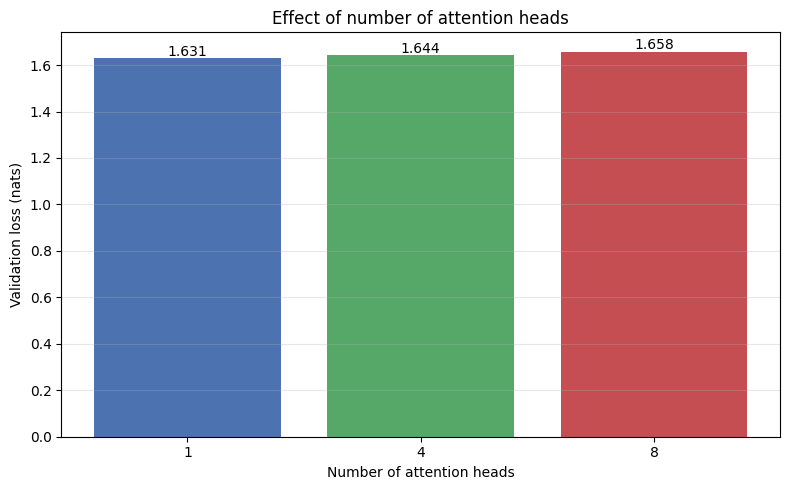

,validation_loss_nats,bits_per_character,training_time_seconds
num_heads,,,
1,1.631,2.353,134.2
4,1.644,2.372,135.5
8,1.658,2.392,139.1


In [42]:
import matplotlib.pyplot as plt
import pandas as pd

heads_table = pd.DataFrame(head_results).T
heads_table.index.name = "num_heads"

heads_table = heads_table.rename(columns={
    "final_val_loss": "validation_loss_nats",
    "final_bits_per_char": "bits_per_character",
    "training_time": "training_time_seconds"
})

heads_table.to_csv("heads_ablation.csv")

plt.figure(figsize=(8, 5))

plt.bar(
    heads_table.index.astype(str),
    heads_table["validation_loss_nats"],
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.xlabel("Number of attention heads")
plt.ylabel("Validation loss (nats)")
plt.title("Effect of number of attention heads")

for i, value in enumerate(heads_table["validation_loss_nats"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("heads_ablation.png", dpi=200, bbox_inches="tight")
plt.show()

heads_table

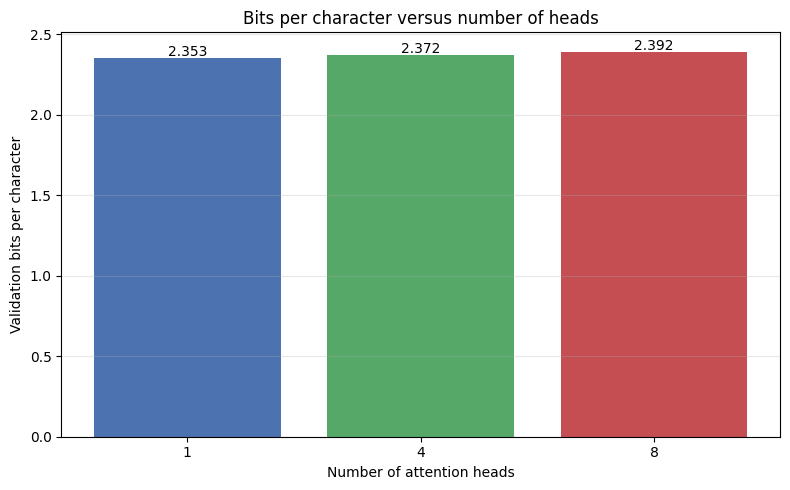

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    heads_table.index.astype(str),
    heads_table["bits_per_character"],
    color=["#4C72B0", "#55A868", "#C44E52"]
)

plt.xlabel("Number of attention heads")
plt.ylabel("Validation bits per character")
plt.title("Bits per character versus number of heads")

for i, value in enumerate(heads_table["bits_per_character"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("heads_ablation_bpc.png", dpi=200, bbox_inches="tight")
plt.show()

In [44]:
import sys
import torch
import torch.nn.functional as F

from shakespeare import download_text, get_batches
from transformer import CharTransformerLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

text = download_text()
chars = sorted(set(text))

stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}

encoded = torch.tensor(
    [stoi[c] for c in text],
    dtype=torch.long
)

causal_model = CharTransformerLM(
    vocab_size=len(chars),
    context=128
).to(device)

optimizer = torch.optim.AdamW(
    causal_model.parameters(),
    lr=3e-4
)

causal_losses = []

NUM_STEPS = 300
BATCH_SIZE = 32

for step in range(NUM_STEPS):
    x, y = get_batches(
        encoded,
        BATCH_SIZE,
        128,
        device
    )

    optimizer.zero_grad()

    _, loss, _ = causal_model(x, y)
    loss.backward()

    optimizer.step()
    causal_losses.append(loss.item())

    if step % 50 == 0 or step == NUM_STEPS - 1:
        print(
            f"causal step {step}: "
            f"loss={loss.item():.4f}"
        )

print("Final causal training loss:", causal_losses[-1])

Using device: cuda
causal step 0: loss=4.3566
causal step 50: loss=2.8891
causal step 100: loss=2.6359
causal step 150: loss=2.6077
causal step 200: loss=2.5457
causal step 250: loss=2.5077
causal step 299: loss=2.4920
Final causal training loss: 2.4920284748077393


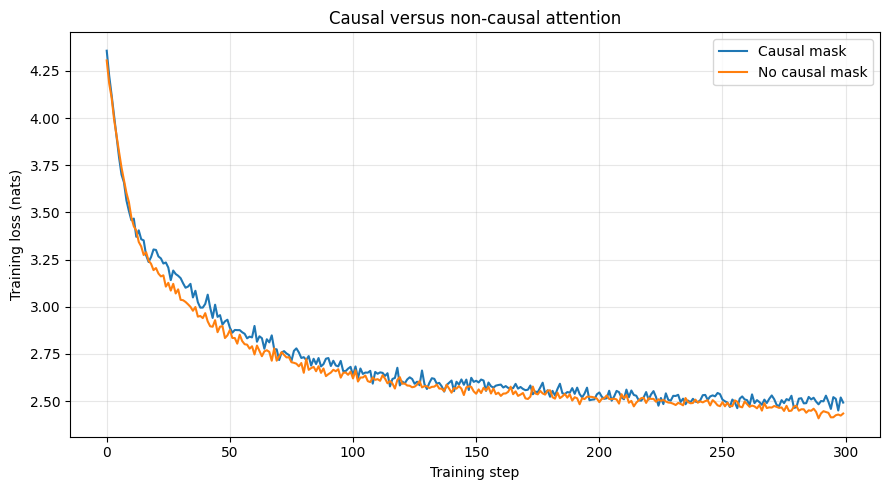

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    causal_losses,
    label="Causal mask"
)

plt.plot(
    losses[:len(causal_losses)],
    label="No causal mask"
)

plt.xlabel("Training step")
plt.ylabel("Training loss (nats)")
plt.title("Causal versus non-causal attention")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "causal_vs_noncausal_loss.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

**KV-cache generation benchmark**

In [46]:
import time
import torch
import torch.nn.functional as F

from attention import scaled_dot_product_attention


@torch.no_grad()
def generate_with_cache(
    model,
    idx,
    max_new_tokens,
    temperature=1.0,
    top_k=None
):
    model.eval()
    device = idx.device

    caches = [None for _ in model.blocks]

    generated = idx

    # Prefill: process the entire prompt once and store K, V.
    B, T = idx.shape
    positions = torch.arange(T, device=device)

    x = model.token_embedding(idx)
    x = x + model.position_embedding(positions)

    for layer_index, block in enumerate(model.blocks):
        attn = block.attn.attn

        x = block.ln1(x)

        q = attn.w_q(x).view(
            B, T, attn.n_heads, attn.d_head
        ).transpose(1, 2)

        k = attn.w_k(x).view(
            B, T, attn.n_heads, attn.d_head
        ).transpose(1, 2)

        v = attn.w_v(x).view(
            B, T, attn.n_heads, attn.d_head
        ).transpose(1, 2)

        causal_mask = torch.tril(
            torch.ones(T, T, dtype=torch.bool, device=device)
        )

        out, _ = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        out = out.transpose(1, 2).contiguous().view(
            B, T, attn.d_model
        )

        x = x + block.dropout(attn.w_o(out))
        x = x + block.ff(block.ln2(x))

        caches[layer_index] = (k, v)

    x = model.ln(x)
    logits = model.head(x)

    logits = logits[:, -1, :] / max(temperature, 1e-8)

    if top_k is not None:
        values, _ = torch.topk(logits, top_k)
        logits[logits < values[:, [-1]]] = float("-inf")

    probs = F.softmax(logits, dim=-1)
    next_token = torch.multinomial(probs, num_samples=1)

    generated = torch.cat([generated, next_token], dim=1)

    # Incremental decoding.
    for _ in range(max_new_tokens - 1):
        current_token = generated[:, -1:]
        current_position = generated.size(1) - 1

        x = model.token_embedding(current_token)
        x = x + model.position_embedding(
            torch.tensor(
                [[current_position]],
                device=device
            )
        )

        B, T, _ = x.shape

        for layer_index, block in enumerate(model.blocks):
            attn = block.attn.attn
            cached_k, cached_v = caches[layer_index]

            x = block.ln1(x)

            q = attn.w_q(x).view(
                B, T, attn.n_heads, attn.d_head
            ).transpose(1, 2)

            k = attn.w_k(x).view(
                B, T, attn.n_heads, attn.d_head
            ).transpose(1, 2)

            v = attn.w_v(x).view(
                B, T, attn.n_heads, attn.d_head
            ).transpose(1, 2)

            k = torch.cat([cached_k, k], dim=2)
            v = torch.cat([cached_v, v], dim=2)

            caches[layer_index] = (k, v)

            out, _ = scaled_dot_product_attention(q, k, v)

            out = out.transpose(1, 2).contiguous().view(
                B, T, attn.d_model
            )

            x = x + block.dropout(attn.w_o(out))
            x = x + block.ff(block.ln2(x))

        x = model.ln(x)
        logits = model.head(x)

        logits = logits[:, -1, :] / max(temperature, 1e-8)

        if top_k is not None:
            values, _ = torch.topk(logits, top_k)
            logits[logits < values[:, [-1]]] = float("-inf")

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        generated = torch.cat(
            [generated, next_token], dim=1
        )

    return generated


def time_generation(
    generation_function,
    model,
    prompt,
    max_new_tokens,
    temperature,
    top_k
):
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.time()
    output = generation_function(
        model,
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.time() - start

    return output, elapsed

In [47]:
from transformer import CharTransformerLM
import torch
import torch.nn.functional as F
import time
from attention import scaled_dot_product_attention

# Redefining generate_with_cache to correctly clamp current_position to model.context - 1
@torch.no_grad()
def generate_with_cache_fixed(
    model,
    idx,
    max_new_tokens,
    temperature=1.0,
    top_k=None
):
    model.eval()
    device = idx.device

    caches = [None for _ in model.blocks]
    generated = idx

    # Prefill: process the entire prompt once and store K, V.
    B, T = idx.shape
    positions = torch.arange(T, device=device)

    x = model.token_embedding(idx)
    x = x + model.position_embedding(positions)

    for layer_index, block in enumerate(model.blocks):
        attn = block.attn.attn
        x = block.ln1(x)

        q = attn.w_q(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)
        k = attn.w_k(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)
        v = attn.w_v(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)

        causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))
        out, _ = scaled_dot_product_attention(q, k, v, mask=causal_mask)
        out = out.transpose(1, 2).contiguous().view(B, T, attn.d_model)

        x = x + block.dropout(attn.w_o(out))
        x = x + block.ff(block.ln2(x))
        caches[layer_index] = (k, v)

    x = model.ln(x)
    logits = model.head(x)
    logits = logits[:, -1, :] / max(temperature, 1e-8)

    if top_k is not None:
        values, _ = torch.topk(logits, top_k)
        logits[logits < values[:, [-1]]] = float("-inf")

    probs = F.softmax(logits, dim=-1)
    next_token = torch.multinomial(probs, num_samples=1)
    generated = torch.cat([generated, next_token], dim=1)

    # Incremental decoding.
    for _ in range(max_new_tokens - 1):
        current_token = generated[:, -1:]
        current_position = generated.size(1) - 1

        # Fix: clamp position index to the maximum context size
        pos_idx = min(current_position, model.context - 1)

        x = model.token_embedding(current_token)
        x = x + model.position_embedding(torch.tensor([[pos_idx]], device=device))

        B, T, _ = x.shape

        for layer_index, block in enumerate(model.blocks):
            attn = block.attn.attn
            cached_k, cached_v = caches[layer_index]

            x = block.ln1(x)

            q = attn.w_q(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)
            k = attn.w_k(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)
            v = attn.w_v(x).view(B, T, attn.n_heads, attn.d_head).transpose(1, 2)

            # If cache exceeds context, slide it
            if cached_k.size(2) >= model.context:
                cached_k = cached_k[:, :, 1:, :]
                cached_v = cached_v[:, :, 1:, :]

            k = torch.cat([cached_k, k], dim=2)
            v = torch.cat([cached_v, v], dim=2)
            caches[layer_index] = (k, v)

            out, _ = scaled_dot_product_attention(q, k, v)
            out = out.transpose(1, 2).contiguous().view(B, T, attn.d_model)

            x = x + block.dropout(attn.w_o(out))
            x = x + block.ff(block.ln2(x))

        x = model.ln(x)
        logits = model.head(x)
        logits = logits[:, -1, :] / max(temperature, 1e-8)

        if top_k is not None:
            values, _ = torch.topk(logits, top_k)
            logits[logits < values[:, [-1]]] = float("-inf")

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        generated = torch.cat([generated, next_token], dim=1)

    return generated

prompt_text = "First Citizen:"
prompt = torch.tensor([[stoi[c] for c in prompt_text]], device=device)

MAX_NEW_TOKENS = 200
TEMPERATURE = 0.8
TOP_K = 40

# Without cache
no_cache_output, no_cache_time = time_generation(
    CharTransformerLM.generate,
    shakespeare_result["model"],
    prompt,
    MAX_NEW_TOKENS,
    TEMPERATURE,
    TOP_K
)

# With KV cache
cache_output, cache_time = time_generation(
    generate_with_cache_fixed,
    shakespeare_result["model"],
    prompt,
    MAX_NEW_TOKENS,
    TEMPERATURE,
    TOP_K
)

speedup = no_cache_time / cache_time

print(f"No-cache generation time: {no_cache_time:.3f} seconds")
print(f"KV-cache generation time: {cache_time:.3f} seconds")
print(f"Speed-up: {speedup:.2f}x")

generation_benchmark = {
    "max_new_tokens": MAX_NEW_TOKENS,
    "no_cache_seconds": no_cache_time,
    "cache_seconds": cache_time,
    "speedup": speedup
}

generation_benchmark

No-cache generation time: 0.854 seconds
KV-cache generation time: 0.780 seconds
Speed-up: 1.10x


{'max_new_tokens': 200,
 'no_cache_seconds': 0.8544094562530518,
 'cache_seconds': 0.7797684669494629,
 'speedup': 1.0957219898819355}

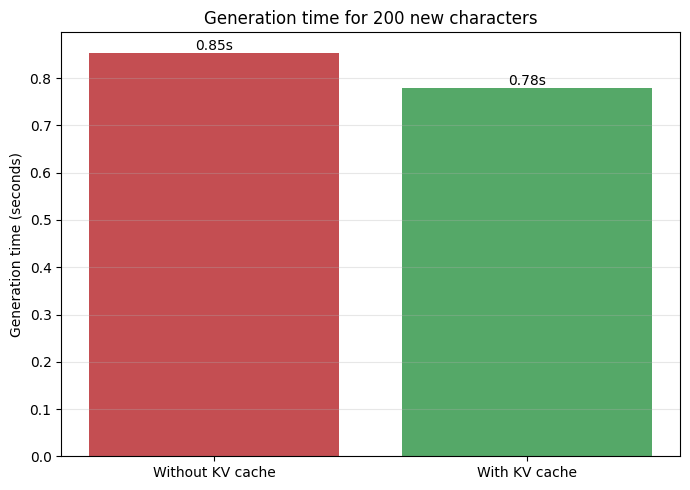

In [48]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Without KV cache", "With KV cache"],
    [no_cache_time, cache_time],
    color=["#C44E52", "#55A868"]
)

plt.ylabel("Generation time (seconds)")
plt.title(
    f"Generation time for {MAX_NEW_TOKENS} new characters"
)

for i, value in enumerate([no_cache_time, cache_time]):
    plt.text(
        i,
        value,
        f"{value:.2f}s",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "kv_cache_generation_time.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [49]:
# Replace the old context-scaling benchmark with this cell.

import time
import torch
import pandas as pd
from transformer import CharTransformerLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

if device != "cuda":
    raise RuntimeError(
        "Peak GPU memory measurement requires a CUDA-enabled runtime. "
        "Switch to a GPU runtime and rerun this cell."
    )

torch.manual_seed(1337)

vocab_size = 65
batch_size = 8
context_lengths = [64, 128, 256, 512]
num_warmup = 3
num_trials = 10

model = CharTransformerLM(
    vocab_size=vocab_size,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    context=512,
    dropout=0.1
).to(device)

model.train()
results = []

for context in context_lengths:
    print(f"\nBenchmarking context length: {context}")

    x = torch.randint(
        0, vocab_size, (batch_size, context), device=device
    )
    y = torch.randint(
        0, vocab_size, (batch_size, context), device=device
    )

    # Warm-up before measuring
    for _ in range(num_warmup):
        model.zero_grad(set_to_none=True)
        _, loss, _ = model(x, y)
        loss.backward()

    model.zero_grad(set_to_none=True)
    torch.cuda.synchronize()

    # Memory already occupied by model and CUDA context
    baseline_allocated = torch.cuda.memory_allocated()

    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    for _ in range(num_trials):
        model.zero_grad(set_to_none=True)

        _, loss, _ = model(x, y)
        loss.backward()

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    peak_allocated = torch.cuda.max_memory_allocated()
    peak_reserved = torch.cuda.max_memory_reserved()

    result = {
        "context": context,
        "seconds_per_step": elapsed / num_trials,
        "peak_allocated_mb": peak_allocated / (1024 ** 2),
        "peak_reserved_mb": peak_reserved / (1024 ** 2),
        "incremental_peak_mb": (
            peak_allocated - baseline_allocated
        ) / (1024 ** 2),
        "device": torch.cuda.get_device_name(0)
    }

    results.append(result)
    print(result)

context_df = pd.DataFrame(results)
context_df.to_csv("context_memory_results.csv", index=False)

print("\nContext-length benchmark results:")
display(context_df)

Device: cuda

Benchmarking context length: 64
{'context': 64, 'seconds_per_step': 0.012422424000010323, 'peak_allocated_mb': 146.107421875, 'peak_reserved_mb': 616.0, 'incremental_peak_mb': 19.5185546875, 'device': 'Tesla T4'}

Benchmarking context length: 128
{'context': 128, 'seconds_per_step': 0.012754384499999105, 'peak_allocated_mb': 174.4443359375, 'peak_reserved_mb': 616.0, 'incremental_peak_mb': 39.78515625, 'device': 'Tesla T4'}

Benchmarking context length: 256
{'context': 256, 'seconds_per_step': 0.013099283800011107, 'peak_allocated_mb': 240.8232421875, 'peak_reserved_mb': 638.0, 'incremental_peak_mb': 84.2109375, 'device': 'Tesla T4'}

Benchmarking context length: 512
{'context': 512, 'seconds_per_step': 0.029487050600005206, 'peak_allocated_mb': 471.0283203125, 'peak_reserved_mb': 862.0, 'incremental_peak_mb': 218.384765625, 'device': 'Tesla T4'}

Context-length benchmark results:


,context,seconds_per_step,peak_allocated_mb,peak_reserved_mb,incremental_peak_mb,device
0,64,0.012422,146.107422,616.0,19.518555,Tesla T4
1,128,0.012754,174.444336,616.0,39.785156,Tesla T4
2,256,0.013099,240.823242,638.0,84.210938,Tesla T4
3,512,0.029487,471.028320,862.0,218.384766,Tesla T4


In [50]:
import sys
import os

# Ensure python looks in the current working directory first
current_dir = os.getcwd()
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

# Clear any cached imports to force a clean load
if "har" in sys.modules:
    del sys.modules["har"]

import random
import numpy as np
import torch
import pandas as pd

from har import train_har_model

seeds = [42, 123, 2026]
positional_encodings = ["none", "sinusoidal", "learned"]

seed_results = []

for seed in seeds:
    for pos_encoding in positional_encodings:

        print("\n" + "=" * 65)
        print("Seed:", seed)
        print("Positional encoding:", pos_encoding)
        print("=" * 65)

        # Set all relevant random seeds before model initialization
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        model, result = train_har_model(
            pos_encoding=pos_encoding,
            patch_size=8,
            d_model=128,
            n_heads=4,
            n_layers=4,
            d_ff=512,
            epochs=10,
            batch_size=64,
            lr=3e-4
        )

        result["seed"] = seed
        seed_results.append(result)

        del model

seed_df = pd.DataFrame(seed_results)
seed_df.to_csv("har_three_seed_results.csv", index=False)

summary_df = (
    seed_df.groupby("pos_encoding")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        training_time_mean=("training_time_sec", "mean"),
        training_time_std=("training_time_sec", "std")
    )
    .reset_index()
)

print("\nIndividual seed results:")
display(seed_df)

print("\nMean and standard deviation across three seeds:")
display(summary_df)

summary_df.to_csv("har_three_seed_summary.csv", index=False)


Seed: 42
Positional encoding: none


Epoch 1/10: 100%|██████████| 115/115 [00:02<00:00, 55.31it/s]


Epoch 1: loss=1.2255, lr=0.000293


Epoch 2/10: 100%|██████████| 115/115 [00:02<00:00, 47.34it/s]


Epoch 2: loss=0.4805, lr=0.000271


Epoch 3/10: 100%|██████████| 115/115 [00:02<00:00, 49.69it/s]


... (174 outputs left out)

Epoch 10: loss=0.0905, lr=0.000000
{'pos_encoding': 'learned', 'patch_size': 8, 'accuracy': 0.9110960298608755, 'parameters': 803712, 'trainable_parameters': 803712, 'training_time_sec': 21.205378770828247}

Individual seed results:


,pos_encoding,patch_size,accuracy,parameters,trainable_parameters,training_time_sec,seed
0,none,8,0.866644,794624,794624,21.931226,42
1,sinusoidal,8,0.897184,794624,794624,21.878695,42
2,learned,8,0.883271,803712,803712,21.815067,42
3,none,8,0.869698,794624,794624,28.739105,123
4,sinusoidal,8,0.889379,794624,794624,21.591904,123
5,learned,8,0.923990,803712,803712,22.681647,123
6,none,8,0.864608,794624,794624,21.190880,2026
7,sinusoidal,8,0.896166,794624,794624,22.195720,2026
8,learned,8,0.911096,803712,803712,21.205379,2026



Mean and standard deviation across three seeds:


,pos_encoding,accuracy_mean,accuracy_std,training_time_mean,training_time_std
0,learned,0.906119,0.020811,21.900698,0.741850
1,none,0.866983,0.002562,23.953737,4.160750
2,sinusoidal,0.894243,0.004243,21.888773,0.302034


In [51]:
# Rerun the main model and head-count ablations with equal settings.

import sys
import os

# Uncache modules so Python loads the fresh files from disk
for mod in ["transformer", "shakespeare"]:
    if mod in sys.modules:
        del sys.modules[mod]

import pandas as pd
import torch
from shakespeare import train_language_model

HEAD_CONFIGURATIONS = [4, 1, 8]
COMMON_STEPS = 5000

fair_results = []

for heads in HEAD_CONFIGURATIONS:

    print("\n" + "=" * 65)
    print(f"Training with {heads} attention head(s)")
    print("=" * 65)

    # train_language_model currently sets torch.manual_seed(1337)
    # internally, so each run starts from the same seed.
    result = train_language_model(
        context=128,
        d_model=128,
        n_heads=heads,
        n_layers=4,
        d_ff=512,
        batch_size=64,
        steps=COMMON_STEPS,
        lr=3e-4
    )

    fair_results.append({
        "num_heads": heads,
        "steps": COMMON_STEPS,
        "final_val_loss": result["final_val_loss"],
        "final_bits_per_char": result["final_bits_per_char"],
        "training_time_sec": result["training_time"]
    })

    del result

fair_df = pd.DataFrame(fair_results)
fair_df.to_csv("fair_head_ablation_results.csv", index=False)

display(fair_df)


Training with 4 attention head(s)
Vocabulary size: 65
Total parameters: 826368
Trainable parameters: 826368


  0%|          | 5/5000 [00:00<10:14,  8.13it/s]

step 0: train_loss=4.3390, val_loss=4.2112, bits_per_char=6.0755


  5%|▌         | 255/5000 [00:09<05:46, 13.70it/s]

step 250: train_loss=2.4771, val_loss=2.4811, bits_per_char=3.5794


 10%|█         | 505/5000 [00:18<05:03, 14.79it/s]

... (121 outputs left out)

100%|██████████| 5000/5000 [03:44<00:00, 22.24it/s]

step 4999: train_loss=1.7206, val_loss=1.8162, bits_per_char=2.6202

Final validation loss: 1.8161993837356567
Final bits per character: 2.6202218441810237
Training time: 224.81510043144226



--- Temperature 0.2 ---
For and the so shall the with the shall with the prose.

KING RICHARD III:
The would the so me the so the so come the sould
The shall and the are the so the preath of the ward
The shall the prope the with the come of the sould
And the come the so shall be the so the so the sould
That the so the would the have the wart the plain
The shall be the pear and the the compers,
And the shall the the wart the come the so the sould
To compe the will the come the to so the come of
The will the shall the sha

--- Temperature 0.8 ---
Fors! my should well, if lord,
And parter a mone in this he noble good quince
To this for they confolds day, whom that with in to fire,
By requen said, and my life in your shall!

CLUCIO:
No your gue of in a and in the ward-stake as
That but that said to me my prone plower
And not not repter and soughty Lary mighty--didest.

OSTUSTUMERD:
I wrish, band my preak, at thou death'st of worse has
and doth doths would thou brother's lish prope?

JULIE

,num_heads,steps,final_val_loss,final_bits_per_char,training_time_sec
0,4,5000,1.790497,2.583141,182.748560
1,1,5000,1.762049,2.542100,145.919776
2,8,5000,1.816199,2.620222,224.815100


**Bonus: LSTM character-level language model**

In [52]:
# Bonus: LSTM baseline for Tiny Shakespeare

import math
import time
import numpy as np
import torch
import torch.nn as nn
import pandas as pd

from shakespeare import download_text, get_batches

# Reproducibility
torch.manual_seed(1337)
np.random.seed(1337)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1337)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Same dataset and character-level encoding as the Transformer
text = download_text()
chars = sorted(set(text))

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encoded = np.array([stoi[ch] for ch in text], dtype=np.int64)

split = int(0.9 * len(encoded))
train_data = torch.from_numpy(encoded[:split])
val_data = torch.from_numpy(encoded[split:])

vocab_size = len(chars)

class CharLSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_layers=2,
        dropout=0.1
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, idx, targets=None):
        x = self.embedding(idx)
        x, _ = self.lstm(x)
        x = self.dropout(x)
        logits = self.output(x)

        loss = None
        if targets is not None:
            loss = nn.functional.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


@torch.no_grad()
def estimate_lstm_loss(
    model,
    data,
    context=128,
    batch_size=64,
    iterations=50
):
    model.eval()
    losses = []

    for _ in range(iterations):
        x, y = get_batches(
            data, batch_size, context, device
        )

        _, loss = model(x, y)
        losses.append(loss.item())

    model.train()
    return float(np.mean(losses))


# Keep the main Transformer experiment's training settings
CONTEXT = 128
BATCH_SIZE = 64
STEPS = 5000
LEARNING_RATE = 3e-4

lstm_model = CharLSTM(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.1
).to(device)

optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=STEPS
)

lstm_train_losses = []
lstm_val_losses = []

start_time = time.time()

for step in range(STEPS):

    x, y = get_batches(
        train_data,
        BATCH_SIZE,
        CONTEXT,
        device
    )

    lstm_model.train()
    optimizer.zero_grad(set_to_none=True)

    _, loss = lstm_model(x, y)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        lstm_model.parameters(), 1.0
    )

    optimizer.step()
    scheduler.step()

    if step % 250 == 0 or step == STEPS - 1:

        val_loss = estimate_lstm_loss(
            lstm_model,
            val_data,
            context=CONTEXT,
            batch_size=BATCH_SIZE
        )

        lstm_train_losses.append(loss.item())
        lstm_val_losses.append(val_loss)

        print(
            f"Step {step}: "
            f"train_loss={loss.item():.4f}, "
            f"val_loss={val_loss:.4f}, "
            f"BPC={val_loss / math.log(2):.4f}"
        )

lstm_training_time = time.time() - start_time

final_lstm_val_loss = lstm_val_losses[-1]
final_lstm_bpc = final_lstm_val_loss / math.log(2)

lstm_result = {
    "model": "LSTM",
    "final_val_loss": final_lstm_val_loss,
    "final_bits_per_char": final_lstm_bpc,
    "training_time_sec": lstm_training_time,
    "steps": STEPS,
    "context": CONTEXT,
    "batch_size": BATCH_SIZE
}

print("\nLSTM character-level results:")
print(lstm_result)

pd.DataFrame([lstm_result]).to_csv(
    "lstm_shakespeare_results.csv",
    index=False
)

torch.save(
    lstm_model.state_dict(),
    "lstm_shakespeare.pt"
)

Step 0: train_loss=4.1658, val_loss=4.1589, BPC=6.0000
Step 250: train_loss=2.5460, val_loss=2.5069, BPC=3.6167
Step 500: train_loss=2.2301, val_loss=2.2071, BPC=3.1841
Step 750: train_loss=2.0918, val_loss=2.0736, BPC=2.9916
Step 1000: train_loss=1.9962, val_loss=1.9942, BPC=2.8771
Step 1250: train_loss=1.8782, val_loss=1.9320, BPC=2.7872
Step 1500: train_loss=1.8323, val_loss=1.8935, BPC=2.7317
Step 1750: train_loss=1.7601, val_loss=1.8603, BPC=2.6838
Step 2000: train_loss=1.7917, val_loss=1.8412, BPC=2.6562
Step 2250: train_loss=1.7644, val_loss=1.8234, BPC=2.6307
Step 2500: train_loss=1.7774, val_loss=1.8000, BPC=2.5969
Step 2750: train_loss=1.6844, val_loss=1.7931, BPC=2.5869
Step 3000: train_loss=1.7278, val_loss=1.7830, BPC=2.5723
Step 3250: train_loss=1.6807, val_loss=1.7767, BPC=2.5632
Step 3500: train_loss=1.6860, val_loss=1.7661, BPC=2.5480
Step 3750: train_loss=1.6722, val_loss=1.7657, BPC=2.5473
Step 4000: train_loss=1.6949, val_loss=1.7620, BPC=2.5420
Step 4250: train_los

In [53]:
# Re-instantiate the model structure locally to count parameters without importing from shakespeare
try:
    lstm_params = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)
except NameError:
    import torch
    import os

    vocab_size = 65 # Default vocabulary size for Tiny Shakespeare
    if os.path.exists("tiny_shakespeare.txt"):
        with open("tiny_shakespeare.txt", "r", encoding="utf-8") as f:
            vocab_size = len(sorted(set(f.read())))

    # Re-create the exact architecture configuration
    local_lstm = torch.nn.LSTM(
        input_size=128,
        hidden_size=128,
        num_layers=2,
        batch_first=True,
        dropout=0.1
    )
    embedding = torch.nn.Embedding(vocab_size, 128)
    output_head = torch.nn.Linear(128, vocab_size)

    lstm_params = (
        sum(p.numel() for p in embedding.parameters()) +
        sum(p.numel() for p in local_lstm.parameters()) +
        sum(p.numel() for p in output_head.parameters())
    )

print(f"LSTM trainable parameters: {lstm_params:,}")

LSTM trainable parameters: 280,897


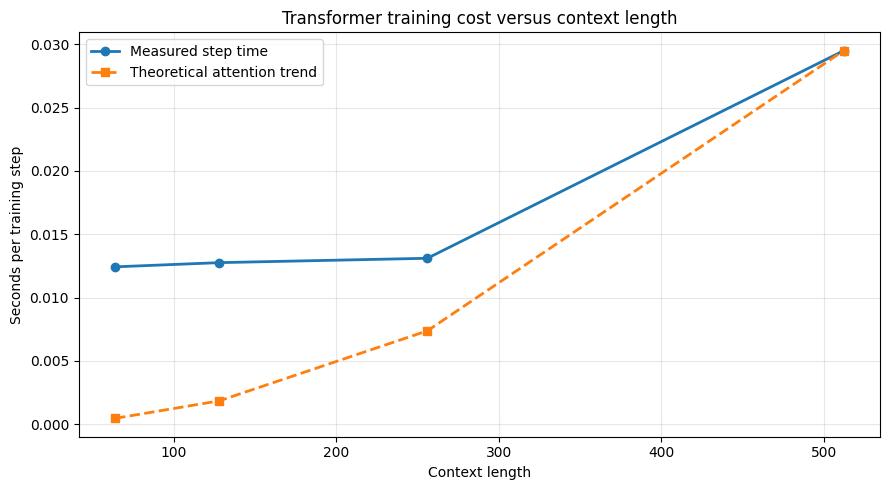

In [54]:
import matplotlib.pyplot as plt

# Dynamically calculate the theoretical quadratic attention operations if missing
if "theoretical_attention_ops" not in context_df.columns:
    context_df["theoretical_attention_ops"] = context_df["context"] ** 2 * 128

plt.figure(figsize=(9, 5))

plt.plot(
    context_df["context"],
    context_df["seconds_per_step"],
    marker="o",
    linewidth=2,
    label="Measured step time"
)

# Normalize theoretical attention cost to the measured time scale.
normalized_theory = (
    context_df["theoretical_attention_ops"]
    / context_df["theoretical_attention_ops"].max()
    * context_df["seconds_per_step"].max()
)

plt.plot(
    context_df["context"],
    normalized_theory,
    "--",
    marker="s",
    linewidth=2,
    label="Theoretical attention trend"
)

plt.xlabel("Context length")
plt.ylabel("Seconds per training step")
plt.title("Transformer training cost versus context length")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "context_scaling_time.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [58]:
# Save the three generated samples to a text file

samples = {
    "Temperature 0.2": shakespeare_result["generations"][0.2],
    "Temperature 0.8": shakespeare_result["generations"][0.8],
    "Temperature 1.5": shakespeare_result["generations"][1.5]
}

with open("generated_samples.txt", "w", encoding="utf-8") as file:
    for label, sample in samples.items():
        file.write(f"===== {label} =====\n")
        file.write(sample[:500])
        file.write("\n\n")

print("generated_samples.txt created successfully!")

from google.colab import files
files.download("generated_samples.txt")

generated_samples.txt created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>